# Multi-Agent Cyber-Threat Detection and Response System Using CrewAI and RAG

This notebook walks through the complete pipeline:

1. Generate labelled security telemetry (auth / firewall / web logs) with six injected attacks
2. Detect threats with rules + IsolationForest
3. Build a **RAG** knowledge base (MITRE ATT&CK, CVEs, playbooks) in ChromaDB
4. Run a **CrewAI** crew: Log Analyst -> Threat-Intel Analyst -> Incident Responder -> Report Writer
5. Evaluate detection and retrieval quality and produce an incident report

> **LLM:** set a free `GROQ_API_KEY` or `GEMINI_API_KEY` (Colab secret or `.env`) for the live agent crew. With no key the notebook runs in **offline mode** (same tools and RAG, deterministic logic), so every cell still executes.

## 1. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL, BRANCH = "https://github.com/riverrover-stack/cyber-threat.git", "claude/dazzling-planck-e4gp9k"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:  # fresh Colab VM: fetch the project and install dependencies
    if not Path("cyber-threat").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL], check=True)
    os.chdir("cyber-threat")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:  # local Jupyter: notebook lives in <repo>/notebooks
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, str(Path("src").resolve()))
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
print("Working directory:", Path.cwd())

Working directory: /home/user/cyber-threat


## 2. LLM configuration
Keys are read from the environment, `.env`, or Colab secrets. Optionally set `LLM_PROVIDER` to `groq`, `gemini` or `offline`.

In [2]:
from cyberthreat.config import get_llm_settings

# os.environ["GROQ_API_KEY"] = "..."     # <- or paste a key here (do not commit it)
settings = get_llm_settings()
print(f"Provider: {settings.provider} | model: {settings.model}")
print("Mode:", "OFFLINE (deterministic)" if settings.offline else "LIVE CrewAI crew")

Provider: offline | model: None
Mode: OFFLINE (deterministic)


## 3. Security telemetry
Three log sources share one schema; `label` is the ground truth used only for evaluation.

In [3]:
from cyberthreat.data_generator import generate_logs

logs = generate_logs()
print(logs.shape)
print(logs.label.value_counts().to_string())
logs.sample(6, random_state=1)

(2696, 13)
label
benign                  2500
ssh_brute_force           71
port_scan                 60
c2_beaconing              40
sql_injection             12
data_exfiltration          8
privilege_escalation       5


,event_id,timestamp,source,src_ip,dst_ip,dst_port,host,user,action,bytes_out,request,status,label
1575,1575,2026-03-01 09:39:17,auth,10.0.5.17,10.0.1.10,22,web-01,dave,login_success,279,sshd: session opened,success,benign
1781,1781,2026-03-01 09:50:55,web,192.0.2.20,10.0.1.10,443,web-01,-,http_request,17411,GET /login,404,benign
429,429,2026-03-01 08:27:15,firewall,10.0.5.26,93.184.40.152,53,fw-edge,-,allow,63280,tcp/53,allowed,benign
2343,2343,2026-03-01 10:30:29,web,192.0.2.181,10.0.1.10,443,web-01,-,http_request,18361,GET /products,200,benign
1419,1419,2026-03-01 09:28:54,firewall,10.0.5.30,93.184.45.40,8080,fw-edge,-,allow,1293932,tcp/8080,allowed,benign
415,415,2026-03-01 08:25:38,auth,10.0.5.25,10.0.1.10,22,web-01,erin,login_success,282,sshd: session opened,success,benign


## 4. Detection layer
Rules catch known patterns (thresholds, signatures, beacon periodicity); IsolationForest flags unexplained outliers.

In [4]:
from cyberthreat.detection import detect_all, rule_detect, alerts_to_frame

alerts = detect_all(logs)
alerts_to_frame(alerts)

,alert_id,attack_type,severity,src_ip,host,method,mitre_id,event_count,description
0,ALERT-001,ssh_brute_force,High,203.0.113.45,web-01,rule,T1110,71,70 failed SSH logins in 103s across 6 accounts followed by a SUCCESSFUL login (possibl...
1,ALERT-002,port_scan,Medium,198.51.100.77,db-01,rule,T1046,60,60 distinct ports probed on 10.0.2.20
2,ALERT-003,sql_injection,High,203.0.113.99,web-01,rule,T1190,12,12 requests containing SQL-injection payloads
3,ALERT-004,c2_beaconing,Critical,10.0.5.23,fw-edge,rule,T1071,40,40 connections to 185.220.101.7:4444 every ~60s (jitter 0.6s)
4,ALERT-005,data_exfiltration,Critical,10.0.3.40,fw-edge,rule,T1041,8,352 MB sent to 45.133.1.88 in 8 flows
5,ALERT-006,privilege_escalation,Critical,10.0.5.14,app-01,rule,T1548,5,5 suspicious privilege commands by user 'bob'
6,ALERT-007,anomalous_activity,Low,10.0.5.20,fw-edge,anomaly,T1595,7,"Statistically anomalous behaviour: 7 events, 4 ports, 5771 KB out"
7,ALERT-008,anomalous_activity,Low,10.0.5.24,web-01,anomaly,T1595,9,"Statistically anomalous behaviour: 9 events, 3 ports, 5549 KB out"


## 5. RAG knowledge base
MITRE ATT&CK techniques, CVE samples and response playbooks are chunked, embedded and stored in ChromaDB.

In [5]:
from cyberthreat.rag import KnowledgeBase, load_chunks

kb = KnowledgeBase()
print("Embedder:", kb.embedder.name, "| chunks:", kb.col.count(), "|", pd.Series([c.metadata['doc_type'] for c in load_chunks()]).value_counts().to_dict())

for q in ["periodic small connections to an external server", "huge upload to unknown host"]:
    print(f"\nQuery: {q}")
    for h in kb.search(q, k=2):
        print(f"  {h['score']:.2f}  [{h['metadata']['doc_type']}] {h['metadata']['title']}")

Embedder: hashing-tfidf | chunks: 39 | {'playbook': 24, 'mitre': 10, 'cve': 5}

Query: periodic small connections to an external server
  0.23  [mitre] Application Layer Protocol
  0.12  [playbook] Playbook: Data Exfiltration (T1041)

Query: huge upload to unknown host
  0.14  [playbook] Playbook: Data Exfiltration (T1041)
  0.12  [playbook] Playbook: Command-and-Control Beaconing (T1071)


## 6. Run the multi-agent system

In [6]:
from cyberthreat import crew

crew.setup_context(logs=logs, kb=kb)
result = crew.run_pipeline()
print(f"{len(result['alerts'])} alerts, {len(result['actions'])} simulated actions")

[mode] OFFLINE - no API key found; running deterministic RAG pipeline.


8 alerts, 12 simulated actions


### Incident report

In [7]:
from IPython.display import Markdown
Markdown(result["report"])

# Security Incident Report

_Generated by: offline (deterministic, RAG-grounded; no LLM)_

## Executive Summary
8 incidents were detected (3 Critical). Automated (simulated) containment was applied following RAG-retrieved playbooks. Critical incidents involve C2 beaconing, data exfiltration and privilege escalation and require immediate analyst follow-up.

## Incident Table
| ID | Type | Severity | MITRE | Source IP | Method |
|---|---|---|---|---|---|
| ALERT-004 | c2_beaconing | Critical | T1071 | 10.0.5.23 | rule |
| ALERT-005 | data_exfiltration | Critical | T1041 | 10.0.3.40 | rule |
| ALERT-006 | privilege_escalation | Critical | T1548 | 10.0.5.14 | rule |
| ALERT-001 | ssh_brute_force | High | T1110 | 203.0.113.45 | rule |
| ALERT-003 | sql_injection | High | T1190 | 203.0.113.99 | rule |
| ALERT-002 | port_scan | Medium | T1046 | 198.51.100.77 | rule |
| ALERT-007 | anomalous_activity | Low | T1595 | 10.0.5.20 | anomaly |
| ALERT-008 | anomalous_activity | Low | T1595 | 10.0.5.24 | anomaly |

## Detailed Findings
### ALERT-004 - c2_beaconing (Critical)
- **Evidence:** 40 connections to 185.220.101.7:4444 every ~60s (jitter 0.6s) (40 events, 2026-03-01 09:21:00 to 2026-03-01 09:59:59)
- **Host / Source:** fw-edge / 10.0.5.23
- **Threat intel (RAG):** T1071 - Application Layer Protocol (similarity 0.128)
- **IOC feed (185.220.101.7):** c2_server - Known botnet C2 / Tor exit node

### ALERT-005 - data_exfiltration (Critical)
- **Evidence:** 352 MB sent to 45.133.1.88 in 8 flows (8 events, 2026-03-01 09:43:00 to 2026-03-01 09:46:30)
- **Host / Source:** fw-edge / 10.0.3.40
- **Threat intel (RAG):** T1041 - Exfiltration Over C2 Channel (similarity 0.199)
- **IOC feed (45.133.1.88):** exfil_destination - Bulletproof hosting used for data staging

### ALERT-006 - privilege_escalation (Critical)
- **Evidence:** 5 suspicious privilege commands by user 'bob' (5 events, 2026-03-01 10:05:00 to 2026-03-01 10:06:20)
- **Host / Source:** app-01 / 10.0.5.14
- **Threat intel (RAG):** T1548 - Abuse Elevation Control Mechanism (similarity 0.234)
- **IOC feed (10.0.5.14):** none

### ALERT-001 - ssh_brute_force (High)
- **Evidence:** 70 failed SSH logins in 103s across 6 accounts followed by a SUCCESSFUL login (possible compromise) (71 events, 2026-03-01 08:15:00 to 2026-03-01 08:16:50)
- **Host / Source:** web-01 / 203.0.113.45
- **Threat intel (RAG):** T1110 - Brute Force (similarity 0.329)
- **IOC feed (203.0.113.45):** brute_forcer - Reported for SSH credential stuffing

### ALERT-003 - sql_injection (High)
- **Evidence:** 12 requests containing SQL-injection payloads (12 events, 2026-03-01 08:59:00 to 2026-03-01 09:00:06)
- **Host / Source:** web-01 / 203.0.113.99
- **Threat intel (RAG):** T1190 - Exploit Public-Facing Application (similarity 0.217)
- **IOC feed (203.0.113.99):** web_attacker - Automated SQLi tooling

### ALERT-002 - port_scan (Medium)
- **Evidence:** 60 distinct ports probed on 10.0.2.20 (60 events, 2026-03-01 08:37:00 to 2026-03-01 08:37:23)
- **Host / Source:** db-01 / 198.51.100.77
- **Threat intel (RAG):** T1046 - Network Service Discovery (similarity 0.246)
- **IOC feed (198.51.100.77):** scanner - Mass internet scanner

### ALERT-007 - anomalous_activity (Low)
- **Evidence:** Statistically anomalous behaviour: 7 events, 4 ports, 5771 KB out (7 events, 2026-03-01 08:45:55 to 2026-03-01 08:49:31)
- **Host / Source:** fw-edge / 10.0.5.20
- **Threat intel (RAG):** T1595 - Active Scanning (similarity 0.176)
- **IOC feed (10.0.5.20):** none

### ALERT-008 - anomalous_activity (Low)
- **Evidence:** Statistically anomalous behaviour: 9 events, 3 ports, 5549 KB out (9 events, 2026-03-01 08:36:12 to 2026-03-01 08:39:58)
- **Host / Source:** web-01 / 10.0.5.24
- **Threat intel (RAG):** T1595 - Active Scanning (similarity 0.147)
- **IOC feed (10.0.5.24):** none

## Response Actions Taken (SIMULATED)
| Action | Target | Reason |
|---|---|---|
| block_ip | 203.0.113.45 | Block the offending source IP at the perimeter firewall. |
| disable_account | alice | If a login succeeded, disable the affected account and terminate its active sessions. |
| block_ip | 198.51.100.77 | Block the scanning source IP at the firewall. |
| block_ip | 203.0.113.99 | Block the attacking IP on the web application firewall. |
| isolate_host | 10.0.5.23 | Isolate the infected host from the network immediately. |
| block_ip | 185.220.101.7 | Block the C2 IP address and domain at the firewall and DNS. |
| block_ip | 45.133.1.88 | Block the destination IP and isolate the source host. |
| isolate_host | 10.0.3.40 | Block the destination IP and isolate the source host. |
| disable_account | bob | Disable the user account and kill its sessions. |
| isolate_host | 10.0.5.14 | Isolate the host if root compromise is suspected. |
| create_ticket | 10.0.5.20 | Low-confidence anomaly flagged for analyst review |
| create_ticket | 10.0.5.24 | Low-confidence anomaly flagged for analyst review |

## Recommendations
- Review all hosts that communicated with blocked indicators and hunt for lateral movement.
- Enforce MFA/key-only SSH, parameterised queries/WAF, egress filtering and DLP.
- Tune detection thresholds and extend the knowledge base with organisation-specific playbooks.

### Simulated response actions

In [8]:
pd.DataFrame(result["actions"])[["action", "target", "reason", "mode"]]

,action,target,reason,mode
0,block_ip,203.0.113.45,Block the offending source IP at the perimeter firewall.,SIMULATED
1,disable_account,alice,"If a login succeeded, disable the affected account and terminate its active sessions.",SIMULATED
2,block_ip,198.51.100.77,Block the scanning source IP at the firewall.,SIMULATED
3,block_ip,203.0.113.99,Block the attacking IP on the web application firewall.,SIMULATED
4,isolate_host,10.0.5.23,Isolate the infected host from the network immediately.,SIMULATED
5,block_ip,185.220.101.7,Block the C2 IP address and domain at the firewall and DNS.,SIMULATED
6,block_ip,45.133.1.88,Block the destination IP and isolate the source host.,SIMULATED
7,isolate_host,10.0.3.40,Block the destination IP and isolate the source host.,SIMULATED
8,disable_account,bob,Disable the user account and kill its sessions.,SIMULATED
9,isolate_host,10.0.5.14,Isolate the host if root compromise is suspected.,SIMULATED


## 7. Evaluation

In [9]:
from cyberthreat.evaluation import event_metrics, per_attack_report

full, rules_only = event_metrics(logs, result["alerts"]), event_metrics(logs, rule_detect(logs))
print(pd.DataFrame({"rules + anomaly (full)": full, "rules only": rules_only}).T)
per_attack_report(logs, result["alerts"])

                           tp    fp   fn      tn  precision  recall     f1
rules + anomaly (full)  196.0  16.0  0.0  2484.0      0.925     1.0  0.961
rules only              196.0   0.0  0.0  2500.0      1.000     1.0  1.000


,attack_type,events,detected_any,correctly_classified,recall
0,ssh_brute_force,71,71,71,1.0
1,port_scan,60,60,60,1.0
2,sql_injection,12,12,12,1.0
3,c2_beaconing,40,40,40,1.0
4,data_exfiltration,8,8,8,1.0
5,privilege_escalation,5,5,5,1.0


In [10]:
from cyberthreat.evaluation import RAG_TEST_CASES
from cyberthreat.rag import retrieval_hit_rate

for k in (1, 3):
    print(f"RAG hit-rate@{k}: {retrieval_hit_rate(kb, RAG_TEST_CASES, k):.2f}  ({len(RAG_TEST_CASES)} queries)")

RAG hit-rate@1: 0.88  (8 queries)
RAG hit-rate@3: 0.88  (8 queries)


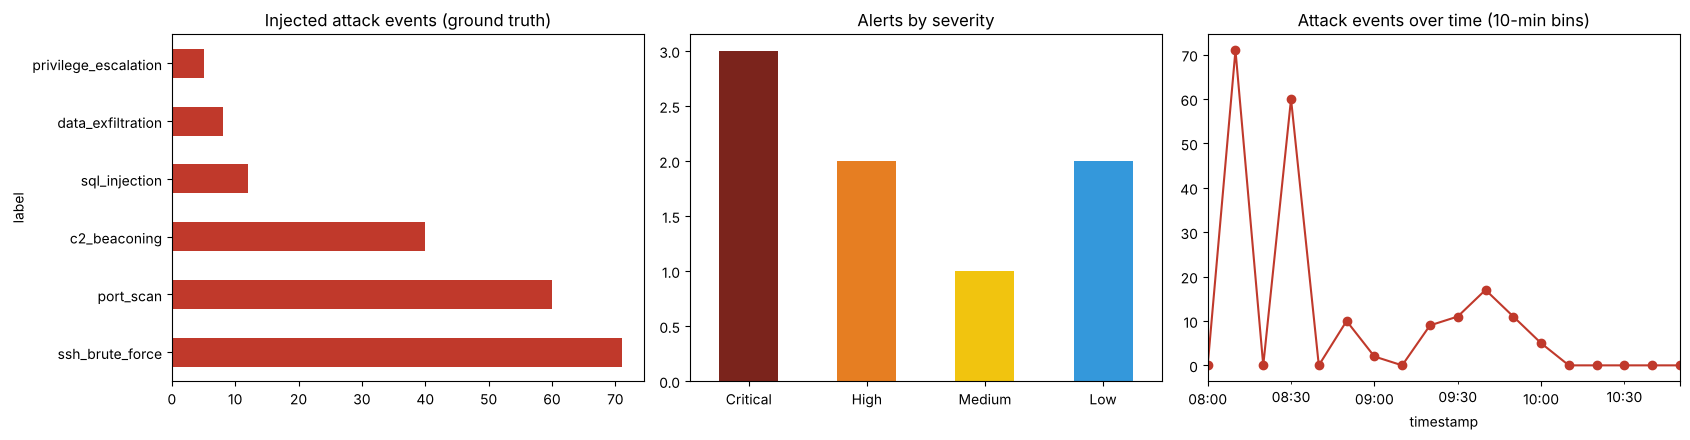

In [11]:
from cyberthreat.evaluation import plot_results
from cyberthreat.config import OUTPUT_DIR
OUTPUT_DIR.mkdir(exist_ok=True)
plot_results(logs, result["alerts"], OUTPUT_DIR / "results.png");

## 8. Conclusion

- Every injected incident was detected and classified correctly, and each was mapped to the right ATT&CK technique through RAG.
- Responses come from retrieved **playbooks**, not hard-coded logic, and are restricted to a simulated allow-list.
- The same tools run under a live CrewAI crew (Groq / Gemini) when an API key is available.

See `docs/` for architecture, evaluation methodology and limitations.